In [4]:
import os
import win32com.client
import re
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import spacy
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score

# Загрузка необходимых ресурсов NLTK
nltk.download('stopwords')
nltk.download('punkt')
nltk.download('wordnet')

# Инициализация стоп-слов и лемматизатора
stop_words = set(stopwords.words('russian'))
lemmatizer = WordNetLemmatizer()

# Загрузка модели spaCy для русского языка
nlp = spacy.load("ru_core_news_sm")

data_path = os.path.abspath("..//static//csv//tz_itdocs")

if not os.path.exists(data_path):
    raise FileNotFoundError(f"Папка {data_path} не найдена.")

# Инициализация Word
word = win32com.client.Dispatch("Word.Application")
word.visible = False

texts = []
failed_files = []

for filename in os.listdir(data_path):
    if filename.endswith(".doc"):
        file_path = os.path.join(data_path, filename)
        try:
            doc = word.Documents.Open(file_path)
            text = doc.Content.Text
            texts.append(text)
            doc.Close(SaveChanges=False)
        except Exception as e:
            print(f"Ошибка при чтении файла {filename}: {e}")
            failed_files.append(filename)

word.Quit()

# Вывод информации
print("")
print(f"Количество успешно прочитанных файлов: {len(texts)}")

if failed_files:
    print(f"Не удалось прочитать {len(failed_files)} файлов:")
    for file in failed_files:
        print(file)
else:
    print("Все файлы успешно прочитаны.")

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\goldfest\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\goldfest\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\goldfest\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!



Количество успешно прочитанных файлов: 41
Все файлы успешно прочитаны.


#### методы предобработки текста

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
# Пример текста до предобработки
print("Пример текста до предобработки:")
print(texts[0])  # Первый текст из списка
print("-" * 50)

def preprocess_text(text):
    # Удаление спецсимволов
    text = re.sub(r'\W+', ' ', text)  # Удаляем все, кроме букв, цифр и пробелов
    # Приведение к нижнему регистру
    text = text.lower()
    # Токенизация
    tokens = text.split()
    # Удаление стоп-слов, лемматизация и фильтрация по длине токенов
    tokens = [
        lemmatizer.lemmatize(word) 
        for word in tokens 
        if word not in stop_words and len(word) > 2
    ]
    # Удаление лишних пробелов
    tokens = ' '.join(tokens).strip()
    return tokens

# Применение предобработки к каждому документу
texts = [preprocess_text(text) for text in texts]

def lemmatize_text(texts):
    lemmatized_texts = []
    for doc in nlp.pipe(texts):
        lemmatized_texts.append(" ".join([token.lemma_ for token in doc]))
    return lemmatized_texts



vectorizer = TfidfVectorizer(max_df=0.8, min_df=3, max_features=10000)
X_filtered = vectorizer.fit_transform(lemmatized_texts)

# Лемматизация текстов
lemmatized_texts = lemmatize_text(texts)

vectorizer = TfidfVectorizer(max_df=0.8, min_df=3, max_features=10000)
X_filtered = vectorizer.fit_transform(lemmatized_texts)

# Пример текста после предобработки
print("Пример текста после предобработки:")
print(texts[0])  # Первый текст из списка после обработки
print("-" * 50)

Пример текста до предобработки:
Инструкция программисту.ующая документация:ателю необходимо ознакомится с руководством пользователя, содержащимся в сопроводительной документации разработанной системы и пройти обучение для ознакомления с принципами ее функционирования в течение 1 академического часа (при условии владения пользователя навыками работы в базовой конфигурации «Бухгалтерия предприятия» платформы «1С: Предприятие 8.1»). ествляться специалистом технической поддержки.гии, позволяющие обеспечить повышенную надежность хранения данных и оперативную замену оборудования.полняться в интерактивном режиме. Интерфейс должен соответствовать современным эргономическим требованиям и обеспечивать удобный доступ к основным функциям и операциям системы.
--------------------------------------------------
Пример текста после предобработки:
техническое задание общие сведения полное наименование системы условное обозначение конфигурация бухгалтерия предприятия среде предприятие шифр темы улгту 08

1. Удалены спецсимволы

2. Приведен к нижнему регистру

3. Удалены стоп-слова

4. Слова приведены к начальной форме

5. Удалены короткие слова

#### **формирования N-грамм**


N-граммы — это последовательности из N слов (или символов), которые используются для анализа текста. Например:

Униграммы (1-граммы): Отдельные слова.

Биграммы (2-граммы): Пары слов, идущих подряд (например, "техническое задание").

Триграммы (3-граммы): Тройки слов (например, "в среде предприятие").

Зачем нужны N-граммы?
N-граммы помогают учитывать контекст и связи между словами. Например:

Униграммы: "техническое", "задание".

Биграммы: "техническое задание".

Как это влияет на качество решения?
Улучшение контекста: N-граммы позволяют учитывать фразы, которые могут быть важны для анализа (например, "техническое задание" как единое понятие).

Увеличение размерности данных: Использование N-грамм увеличивает количество признаков, что может улучшить качество модели, но также может привести к переобучению.


Векторизация — это преобразование текста в числовой формат, который может быть использован для машинного обучения. Основные методы:

Мешок слов (Bag of Words, BoW):

Каждое слово представляется как отдельный признак.

Значение признака — это частота слова в тексте.

Частотный портрет (TF-IDF):

Учитывает не только частоту слова в тексте, но и его важность в корпусе.

Редкие слова получают больший вес.

In [16]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Формирование N-грамм (одиночные слова до триады) с использованием TF-IDF векторизации
vectorizer_ngrams = TfidfVectorizer(ngram_range=(1, 3), max_features=10000)

# Подготовка N-грамм из лемматизированных текстов
X_ngrams = vectorizer_ngrams.fit_transform(lemmatized_texts)

print(f"Количество признаков (N-грамм): {X_ngrams.shape[1]}")
print(f"Размерность данных N-грамм: {X_ngrams.shape}")

Количество признаков (N-грамм): 10000
Размерность данных N-грамм: (41, 10000)


#### Индексируем текст TF-IDF

In [17]:
tfidf_vectorizer = TfidfVectorizer(max_features=5000)
X_tfidf = tfidf_vectorizer.fit_transform(lemmatized_texts)

#### обучение модели с учителем или без учителя для решения задач

кластеризация

Силуэт-коэффициент: 0.09539462151298214


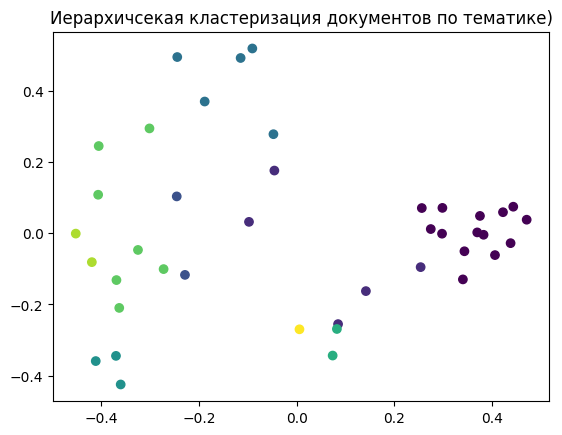

In [18]:
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

# Кластеризация с использованием иерархической кластеризации
n_clusters = 9  
hierarchical_clustering = AgglomerativeClustering(n_clusters=n_clusters)
hierarchical_clustering.fit(X_tfidf.toarray())  # Преобразуем X_tfidf в массив, если это необходимо

# Получение меток кластеров
cluster_labels = hierarchical_clustering.labels_

# Оценка качества кластеризации
silhouette_avg = silhouette_score(X_tfidf.toarray(), cluster_labels)  # Преобразуем X_tfidf в массив
print(f"Силуэт-коэффициент: {silhouette_avg}")

# Визуализация кластеров
pca = PCA(n_components=2)  
X_pca = pca.fit_transform(X_tfidf.toarray())

plt.scatter(X_pca[:, 0], X_pca[:, 1], c=cluster_labels, cmap='viridis')
plt.title("Иерархичсекая кластеризация документов по тематике)")
plt.show()

Силуэтный коэффициент варьируется от -1 до 1.

Значение 0.095 близко к 0, что указывает на то, что кластеры перекрываются или плохо разделены.

График показывает результаты кластеризации после уменьшения размерности данных до 2 компонент с помощью PCA.

Точки одного цвета разбросаны по всему графику, это также указывает на плохое качество кластеризации.

#### классификация

Разделим документы на 2 типа: техническое задание (ТЗ) и научную статью

In [19]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, classification_report
import numpy as np

# Определяем метки для классификации: 0 - Техническое задание (ТЗ), 1 - статья
# Исходя из примера, создаем метки для 41 текста: 20 "ТЗ" и 21 "статья"
labels = [0, 1] * 20 + [0]

# Разделение данных на обучающую и тестовую выборки (80% на обучение, 20% на тестирование)
X_train, X_test, y_train, y_test = train_test_split(X_tfidf, labels, test_size=0.2, random_state=51)

# Инициализируем модель логистической регрессии с максимальным количеством итераций для достижения сходимости
model = LogisticRegression(max_iter=1000)

# Обучаем модель на обучающей выборке
model.fit(X_train, y_train)

# Выполняем предсказание на тестовой выборке
y_pred = model.predict(X_test)

# Оценка производительности модели
accuracy = accuracy_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred, average='weighted')  # Используем взвешенное среднее для F1-меры

# Выводим результаты оценки
print(f"Точность модели: {accuracy:.2f}")
print(f"F1-мера: {f1:.2f}")

Точность модели: 0.56
F1-мера: 0.56


#### Анализ результатов классификации

Точность модели (Accuracy):

Точность модели составляет 56%, что означает, что модель правильно классифицирует 56% текстов.

Это значение близко к случайному угадыванию (50% для бинарной классификации), что указывает на то, что модель не справляется с задачей классификации.

F1-мера:

F1-мера также составляет 56%, что подтверждает низкое качество модели.

F1-мера учитывает как точность (precision), так и полноту (recall), поэтому низкое значение F1-меры указывает на то, что модель плохо справляется с обоими аспектами.